In [1]:
import numpy as np
import random
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

from networkx.algorithms.community import louvain_communities, modularity

# Fix the random seeds so the results are reproducible
random.seed(42)
np.random.seed(42)


## Assignment 3

The graph-tool part (Question 1b and 1c) is in `assignment03_graphtool.ipynb`.

#### Question 01 - Community detection, degree heterogeneity, and graph-tool

#### 1.a

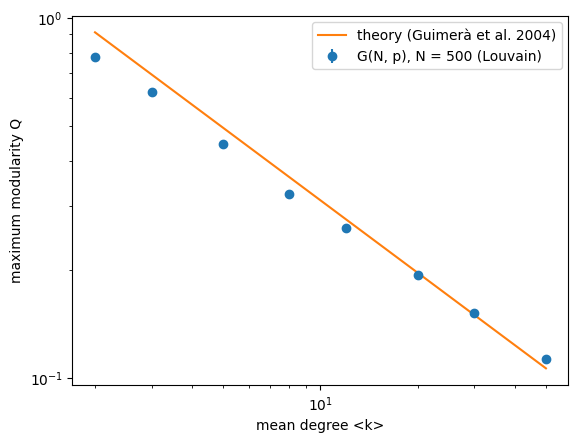

<k> =  2:  Q = 0.779
<k> =  3:  Q = 0.621
<k> =  5:  Q = 0.446
<k> =  8:  Q = 0.324
<k> = 12:  Q = 0.261
<k> = 20:  Q = 0.193
<k> = 30:  Q = 0.151
<k> = 50:  Q = 0.113


In [2]:
# Maximum modularity of G(N, p) random graphs as a function of the mean degree <k>
N = 500
degrees = [2, 3, 5, 8, 12, 20, 30, 50]   # mean degree <k>
samples = 5                              # random graphs per value of <k>

Q_mean, Q_std = [], []
for k in degrees:
    Qs = []
    for s in range(samples):
        G = nx.gnp_random_graph(N, k / (N - 1))
        communities = louvain_communities(G)     # Louvain gives a lower bound on the maximum modularity
        Qs.append(modularity(G, communities))
    Q_mean.append(np.mean(Qs))
    Q_std.append(np.std(Qs))

# Theoretical prediction of Guimerà et al. (2004): Q ≈ (1 - 2/sqrt(N)) (2/<k>)^(2/3)
k_theory = np.linspace(2, 50, 100)
Q_theory = (1 - 2 / np.sqrt(N)) * (2 / k_theory) ** (2 / 3)

plt.errorbar(degrees, Q_mean, yerr=Q_std, fmt="o", label=f"G(N, p), N = {N} (Louvain)")
plt.plot(k_theory, Q_theory, "-", label="theory (Guimerà et al. 2004)")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("mean degree <k>")
plt.ylabel("maximum modularity Q")
plt.legend()
plt.savefig("fig2_guimera.png", dpi=150, bbox_inches="tight")
plt.show()

for k, q in zip(degrees, Q_mean):
    print(f"<k> = {k:>2}:  Q = {q:.3f}")


The figure shows that random graphs, which have no communities at all, still reach high modularity: about 0.78 when the graph is sparse (⟨k⟩ = 2) and still about 0.32 at ⟨k⟩ = 8. Modularity decreases as the graph gets denser, following the power law Q ∝ ⟨k⟩^(-2/3) predicted by Guimerà et al. (straight line on log-log axes). Our points lie slightly below the theory for sparse graphs and close to it for denser ones. This is expected: Louvain only finds a lower bound of the true maximum modularity (the paper uses simulated annealing), and the formula is derived for not-too-sparse graphs.

This happens because the algorithm searches through so many possible partitions that it always finds one where, just by chance, a few more edges than expected fall inside groups. So high modularity can come from random noise, not real structure.

This means modularity is not a reliable measure of partition quality on its own. A value like 0.3 isn't meaningful unless it is clearly higher than what a random graph with the same size and density would give. Modularity also always finds some partition, so it can never tell us that a network has no communities.

#### 1.d

**Intuition.** In the normal SBM, all nodes in the same group are treated as equivalent, so they are expected to have about the same number of connections. But in real networks, some nodes have many connections (hubs) and most have few. To explain this, the normal SBM ends up grouping nodes by how many connections they have, not by who they connect to. Figure 7a shows this for polblogs: with two groups, the SBM separates popular blogs from less popular ones and misses the liberal/conservative split. Degree correction fixes this by giving each node its own parameter θ_i, which controls how many connections it gets. The degrees are explained by θ, and the groups only need to explain who connects to whom. With this change, the DC-SBM finds the two political groups (Figure 7b), matching our result in (b).

**Formalism.** In the microcanonical version, the network is generated in three steps (Figure 8):
1. Given the groups b, choose how many edges connect each pair of groups (the matrix e).
2. Choose the degree of each node, so that the degrees in each group add up to the edges of that group.
3. Place the edges randomly, respecting both the group edge counts and the node degrees.

This gives P(A | b) = P(A | k, e, b) · P(k | e, b) · P(e | b).

The description length is Σ = −log P(A | k, e, b) − log P(k, e, b). The first term measures how much information we need to describe the network once we know the model. The second term measures how much information we need to describe the model itself. A more complex model fits the data better but costs more to describe, so the best model balances the two.

**Model selection.** Adding θ means adding many new parameters, so we need to check that degree correction is really worth it. We compare the description lengths of the two models and prefer the smaller one. For polblogs, the DC-SBM has the smaller description length, which agrees with what we found in (c): it reached a lower description length with fewer blocks (5 vs 15).

#### Question 02 - Random walk dynamics

In [3]:
# Average time for a random walker to go from i to j and back to i
def commute_time(G, i, j, n=1000):
    total = 0
    for _ in range(n):
        node = i
        steps = 0
        reached_j = False
        while True:
            node = random.choice(list(G[node]))  # move to a random neighbor
            steps += 1
            if node == j:
                reached_j = True
            if reached_j and node == i:
                break
        total += steps
    return total / n

# Test on the karate club graph with three random pairs
G = nx.karate_club_graph()
for _ in range(3):
    i, j = random.sample(list(G.nodes()), 2)
    print(f"Commute time between {i} and {j}: {commute_time(G, i, j):.2f}")

Commute time between 3 and 25: 125.33
Commute time between 8 and 9: 113.68
Commute time between 2 and 1: 35.38


In [4]:
# Mean commute time over all pairs of nodes
def mean_commute_time(G):
    L = nx.laplacian_matrix(G, weight=None).toarray()
    Lp = np.linalg.pinv(L)
    d = np.diag(Lp)
    C = 2 * G.number_of_edges() * (d[:, None] + d[None, :] - 2 * Lp)  # all pairs at once
    n = G.number_of_nodes()
    return C.sum() / (n * (n - 1))  # average over pairs (diagonal is 0)

er = []
ba = []
for s in range(10):
    # Erdős–Rényi with N = 500 and <k> = 8, largest connected component
    G = nx.gnp_random_graph(500, 8 / 499)
    G = G.subgraph(max(nx.connected_components(G), key=len))
    er.append(mean_commute_time(G))

    # Barabási–Albert with N = 500 and m = 4 (always connected)
    G = nx.barabasi_albert_graph(500, 4)
    ba.append(mean_commute_time(G))

print("ER mean commute time:", np.mean(er))
print("BA mean commute time:", np.mean(ba))

ER mean commute time: 1364.946994119347
BA mean commute time: 1584.0047207754474


The mean commute time is higher in the Barabási–Albert networks (about 1584) than in the Erdős–Rényi networks (about 1365), even though both have almost the same number of nodes and edges.

The reason is the difference in degrees. A random walker finds high-degree nodes easily, because many edges lead to them, but needs a long time to find low-degree nodes. In BA networks, a few hubs have many connections and most nodes have only a few. The walker keeps passing through the hubs and takes a long time to reach a specific node with few connections. In ER networks, most nodes have a degree close to 8, so they are all about equally easy to reach, and the commute time is shorter on average.

#### Question 03 - Core concepts in network science

#### a)

**Concept: Link prediction**

Link prediction asks a simple question: given a network, which pairs of nodes that are not connected are likely to be connected, either now (a link we missed) or in the future (a link that will form)?

The basic idea is that the structure of a network tells us where links are likely. The simplest methods give each unconnected pair a score based on their neighborhoods. The common neighbors score counts how many friends two people share: if they have many friends in common, they are likely to meet. The Jaccard index does the same but divides by the total number of their neighbors, so that very popular nodes don't get high scores just because they know everyone. The Adamic–Adar index gives more weight to shared neighbors that have few connections, because a friend who knows only a few people is a stronger hint than a celebrity everyone follows. Preferential attachment simply multiplies the two degrees, assuming that popular nodes tend to connect with each other. More advanced methods fit a model to the network, such as a stochastic block model, and predict links that the model considers likely.

To test a method, we remove some existing links, ask the method to rank all unconnected pairs, and check whether the removed links end up near the top of the ranking.

Link prediction is useful in many areas: suggesting friends on social media, recommending products to buy, finding interactions between proteins or drugs that haven't been tested yet, and detecting links that are missing from or wrongly included in incomplete data.

#### b)

What confuses me most: how can we test a prediction about links that don't exist?

The part of link prediction that I find most confusing is how we evaluate it. At first it seems like a circular problem. We want to predict links that are missing from the network, but if they are missing, we have no way of knowing whether a prediction is right or wrong. And every pair of nodes that is not connected looks the same in the data: we can't tell a link that is truly absent from one that exists but wasn't recorded, or one that will form in the future.

My understanding. The trick is to create the missing links ourselves. We take the network, randomly hide some edges (for example 10%), and treat them as the "answers." The method only sees the remaining 90% and gives a score to every unconnected pair. Then we check how many of the hidden edges are near the top of the ranking.

A small example helps me see it. Imagine a network where Anna, Ben, and Carla are all friends with each other. I hide the edge between Anna and Ben. Now the method sees that Anna and Ben share a common friend, Carla, so it gives them a high score. Meanwhile, Anna and a stranger from another part of the network share no friends, so they get a score of zero. If the hidden edge (Anna–Ben) ends up ranked above most of the other pairs, the method did well.

What still feels strange to me. Even with this approach, the pairs that we count as "wrong" are not necessarily wrong. If the method ranks Anna and a stranger highly and they are not connected, we call it a mistake, but they might become friends tomorrow, or they might already be friends and the link is missing from the data. So the evaluation only measures how well a method recovers the structure we already have, not whether it truly predicts the future.

A second problem is the numbers. In a network of 1,000 nodes, there are almost 500,000 possible pairs, and usually only a few thousand edges. So almost all pairs are not connected. A method can look very good on some measures just by predicting that nothing is connected. This is why it matters which measure we use: the AUC asks whether a hidden edge is usually ranked above a random unconnected pair, while precision asks how many of the top guesses are actually correct, which is a much harder test.

Thinking about it this way, I understand link prediction less as "predicting the future" and more as "learning the patterns that explain where links are, and checking whether those patterns can recover links we hid on purpose."

#### c)

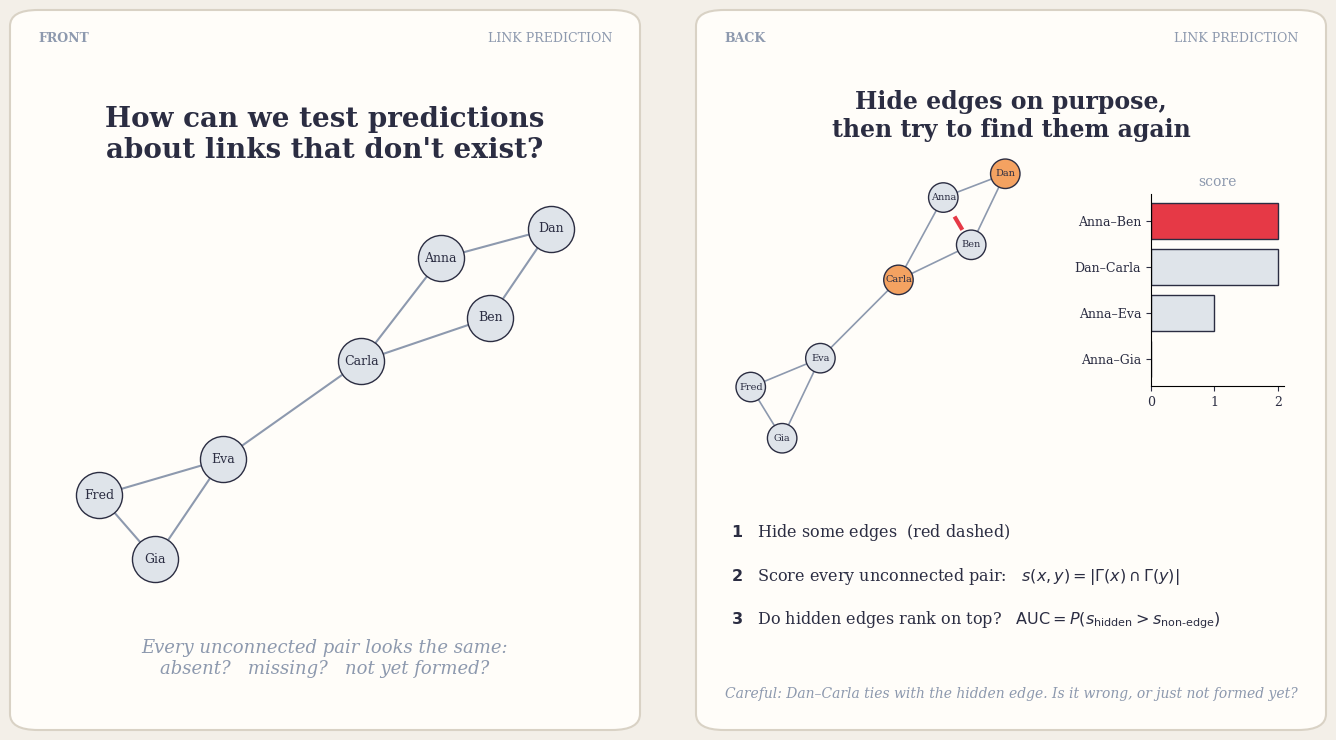

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Colors
BG, CARD, INK, SOFT = "#f3efe8", "#fffdf9", "#2b2d42", "#8d99ae"
NODE, ACCENT, HIDDEN = "#dfe4ea", "#f4a261", "#e63946"

# A small friendship network
G = nx.Graph()
G.add_edges_from([
    ("Anna", "Carla"), ("Ben", "Carla"), ("Anna", "Ben"),
    ("Anna", "Dan"), ("Ben", "Dan"),
    ("Carla", "Eva"), ("Eva", "Fred"), ("Fred", "Gia"), ("Eva", "Gia"),
])
pos = nx.spring_layout(G, seed=3)

# Hide one edge: the "answer" the method should find
hidden = ("Anna", "Ben")
G_obs = G.copy()
G_obs.remove_edge(*hidden)
common = list(nx.common_neighbors(G_obs, *hidden))

# Common-neighbor scores for a few unconnected pairs
pairs = [("Anna", "Ben"), ("Dan", "Carla"), ("Anna", "Eva"), ("Anna", "Gia")]
scores = [len(list(nx.common_neighbors(G_obs, a, b))) for a, b in pairs]

plt.rcParams["font.family"] = "serif"
fig = plt.figure(figsize=(14, 8), facecolor=BG)

for k, label in enumerate(["FRONT", "BACK"]):
    # Rounded card
    x0 = 0.03 + k * 0.49
    fig.patches.append(FancyBboxPatch((x0, 0.05), 0.45, 0.9, boxstyle="round,pad=0,rounding_size=0.02",
                                      transform=fig.transFigure, facecolor=CARD, edgecolor="#d9d2c5", lw=1.5, zorder=-1))
    fig.text(x0 + 0.02, 0.91, label, fontsize=9, color=SOFT, fontweight="bold")
    fig.text(x0 + 0.43, 0.91, "LINK PREDICTION", fontsize=9, color=SOFT, ha="right")

# ---------- FRONT ----------
fig.text(0.255, 0.83, "How can we test predictions\nabout links that don't exist?",
         ha="center", va="top", fontsize=20, fontweight="bold", color=INK)
ax1 = fig.add_axes([0.06, 0.22, 0.39, 0.5], facecolor="none")
nx.draw_networkx_edges(G_obs, pos, ax=ax1, edge_color=SOFT, width=1.5)
nx.draw_networkx_nodes(G_obs, pos, ax=ax1, node_color=NODE, node_size=1100, edgecolors=INK, linewidths=1)
nx.draw_networkx_labels(G_obs, pos, ax=ax1, font_size=9, font_color=INK, font_family="serif")
ax1.axis("off")
fig.text(0.255, 0.12, "Every unconnected pair looks the same:\nabsent?   missing?   not yet formed?",
         ha="center", fontsize=13, style="italic", color=SOFT)

# ---------- BACK ----------
fig.text(0.745, 0.85, "Hide edges on purpose,\nthen try to find them again",
         ha="center", va="top", fontsize=17, fontweight="bold", color=INK)
ax2 = fig.add_axes([0.54, 0.38, 0.22, 0.40], facecolor="none")
colors = [ACCENT if n in common else NODE for n in G_obs]
nx.draw_networkx_edges(G_obs, pos, ax=ax2, edge_color=SOFT, width=1.2)
nx.draw_networkx_edges(G, pos, edgelist=[hidden], ax=ax2, style="dashed", edge_color=HIDDEN, width=3)
nx.draw_networkx_nodes(G_obs, pos, ax=ax2, node_color=colors, node_size=450, edgecolors=INK, linewidths=1)
nx.draw_networkx_labels(G_obs, pos, ax=ax2, font_size=7, font_color=INK, font_family="serif")
ax2.axis("off")

# Bar chart of scores
ax3 = fig.add_axes([0.845, 0.48, 0.095, 0.24], facecolor="none")
bar_colors = [HIDDEN if p == hidden else NODE for p in pairs]
ax3.barh([f"{a}–{b}" for a, b in pairs], scores, color=bar_colors, edgecolor=INK)
ax3.invert_yaxis()
ax3.set_title("score", fontsize=10, color=SOFT)
ax3.tick_params(labelsize=9, colors=INK)
for side in ["top", "right"]:
    ax3.spines[side].set_visible(False)

# Steps and formulas
steps = (
    r"$\mathbf{1}$   Hide some edges  (red dashed)" "\n\n"
    r"$\mathbf{2}$   Score every unconnected pair:   $s(x,y) = |\Gamma(x) \cap \Gamma(y)|$" "\n\n"
    r"$\mathbf{3}$   Do hidden edges rank on top?   $\mathrm{AUC} = P(s_{\mathrm{hidden}} > s_{\mathrm{non\text{-}edge}})$"
)
fig.text(0.545, 0.31, steps, fontsize=11.5, color=INK, va="top")
fig.text(0.745, 0.09, "Careful: Dan–Carla ties with the hidden edge. Is it wrong, or just not formed yet?",
         ha="center", fontsize=10, style="italic", color=SOFT)

plt.savefig("flashcard.png", dpi=200, facecolor=BG)
plt.show()

#### Question 04 - Epidemic thresholds on networks

#### a)

1222 nodes, 16714 edges


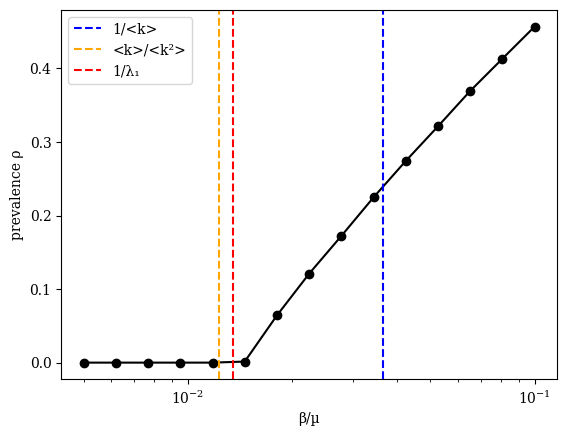

In [6]:
# Load polblogs: undirected, no repeated edges, no self-loops, largest component
edges = pd.read_csv("network/edges.csv")
G = nx.Graph()                                   # nx.Graph removes repeated edges
G.add_edges_from(edges.iloc[:, :2].values)       # first two columns: source, target
G.remove_edges_from(nx.selfloop_edges(G))
G = G.subgraph(max(nx.connected_components(G), key=len))
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")  # 1222 and 16714

A = nx.to_scipy_sparse_array(G)
N = A.shape[0]

# One SIS run
def sis(beta, mu):
    x = np.random.rand(N) < 0.5                  # half of the nodes infected
    rho = 0
    for t in range(1500):
        n = A @ x                                # infected neighbors
        new = ~x & (np.random.rand(N) < 1 - (1 - beta) ** n)
        x = (x & (np.random.rand(N) > mu)) | new
        if t >= 1000:
            rho += x.mean() / 500                # average of the last 500 steps
    return rho

# Simulate
mu = 0.1
ratios = np.logspace(np.log10(0.005), np.log10(0.1), 15)
rhos = [np.mean([sis(r * mu, mu) for _ in range(10)]) for r in ratios]

# Thresholds
k = A.sum(axis=1)                                # degrees
lam = np.linalg.eigvalsh(A.toarray()).max()

# Plot
plt.semilogx(ratios, rhos, "o-", color="black")
plt.axvline(1 / k.mean(), ls="--", color="blue", label="1/<k>")
plt.axvline(k.mean() / (k**2).mean(), ls="--", color="orange", label="<k>/<k²>")
plt.axvline(1 / lam, ls="--", color="red", label="1/λ₁")
plt.xlabel("β/µ")
plt.ylabel("prevalence ρ")
plt.legend()
plt.show()

The simulation shows a clear epidemic threshold: below β/µ ≈ 0.015, the infection always dies out, and above it, a growing fraction of the network stays infected. The two predictions that take the network's degree heterogeneity into account, ⟨k⟩/⟨k²⟩ and 1/λ₁, are both close to this value, with 1/λ₁ matching the start of the epidemic slightly better. The prediction 1/⟨k⟩, which treats every node as if it had the average degree, is about 2.5 times too high (0.037 vs. 0.012 for ⟨k⟩/⟨k²⟩ and 0.013 for 1/λ₁).

This tells us that the epidemic threshold depends on the structure of the network, not just on its average degree. Polblogs has a few hubs with many connections. These hubs get infected easily and pass the infection to many other nodes, so they can keep the epidemic alive even when the infection rate is low. A prediction based only on the average degree ignores these hubs, and so it overestimates how strong the infection must be to spread. In networks with very heterogeneous degrees, the threshold becomes much lower, which makes these networks especially vulnerable to epidemics.

#### b) Immunization

The code below runs the three strategies once and is used for both (i) and (iv).

random stops the epidemic at g = 0.7
random predicted threshold (1/λ1 ≥ β/µ) at g = 0.8
targeted stops the epidemic at g = 0.1
targeted predicted threshold (1/λ1 ≥ β/µ) at g = 0.15
acquaintance stops the epidemic at g = 0.25
acquaintance predicted threshold (1/λ1 ≥ β/µ) at g = 0.3


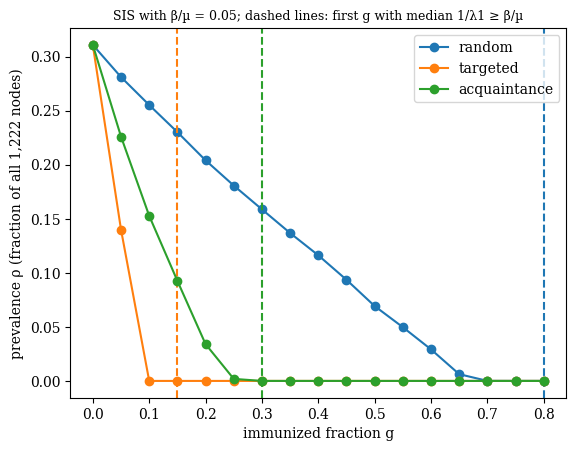

In [7]:
N = G.number_of_nodes()
nodes = list(G.nodes())

# SIS on the remaining network: returns the prevalence and whether it died out
def sis(H, beta=0.005, mu=0.1):
    A = nx.to_scipy_sparse_array(H)
    n = A.shape[0]
    x = np.random.rand(n) < 0.5
    rho = 0
    for t in range(1500):
        new = ~x & (np.random.rand(n) < 1 - (1 - beta) ** (A @ x))
        x = (x & (np.random.rand(n) > mu)) | new
        if t >= 1000:
            rho += x.sum() / N / 500
    return rho, x.sum() == 0

# 1/λ1 of a network (infinity if no edges are left)
def inv_lambda(H):
    if H.number_of_edges() == 0:
        return np.inf
    return 1 / np.linalg.eigvalsh(nx.to_numpy_array(H)).max()

# Immunization orders
def random_order():
    return random.sample(nodes, N)

def targeted_order():
    return sorted(nodes, key=G.degree, reverse=True)

def acquaintance_order():
    order = []
    while len(order) < 0.8 * N:
        u = random.choice(list(G[random.choice(nodes)]))
        if u not in order:
            order.append(u)
    return order

strategies = {"random": random_order, "targeted": targeted_order, "acquaintance": acquaintance_order}
gs = np.linspace(0, 0.8, 17)

for name, make_order in strategies.items():
    rho_mean = np.zeros(len(gs))
    died = np.zeros(len(gs))
    inv = np.zeros((10, len(gs)))                     # 1/λ1 for each run and each g
    for run in range(10):
        order = make_order()
        for i, g in enumerate(gs):
            H = G.copy()
            H.remove_nodes_from(order[:int(g * N)])
            rho, dead = sis(H)
            rho_mean[i] += rho / 10
            died[i] += dead
            inv[run, i] = inv_lambda(H)

    line, = plt.plot(gs, rho_mean, "o-", label=name)

    # i. first g where all 10 runs died out
    if (died == 10).any():
        print(name, "stops the epidemic at g =", round(gs[died == 10][0], 2))
    else:
        print(name, "does not stop the epidemic in the tested range")

    # iv. first g where the median 1/λ1 reaches β/µ = 0.05
    median = np.median(inv, axis=0)
    if (median >= 0.05).any():
        g_pred = gs[median >= 0.05][0]
        plt.axvline(g_pred, ls="--", color=line.get_color())
        print(name, "predicted threshold (1/λ1 ≥ β/µ) at g =", round(g_pred, 2))
    else:
        print(name, "1/λ1 never reaches β/µ in the tested range")

plt.xlabel("immunized fraction g")
plt.ylabel("prevalence ρ (fraction of all 1,222 nodes)")
plt.title("SIS with β/µ = 0.05; dashed lines: first g with median 1/λ1 ≥ β/µ", fontsize=9)
plt.legend()
plt.show()

#### b.i)

The first tested g at which all 10 runs died out within 1500 steps is:

| strategy | g that stops the epidemic |
|---|---|
| random | 0.70 |
| targeted | 0.10 |
| acquaintance | 0.25 |

Targeted immunization is by far the most efficient: immunizing the 10% highest-degree nodes is enough. Acquaintance immunization needs 25%, still much less than random immunization, which needs to remove 70% of the nodes.

#### b.ii)

Acquaintance immunization works because of the friendship paradox: your friends usually have more friends than you do. When we pick a random person and then one of their contacts, we are more likely to land on a hub, because hubs are connected to many people. So this strategy ends up immunizing hubs without ever measuring anyone's degree.

In our simulations this is clear: acquaintance immunization stops the epidemic at g = 0.25, against 0.70 for random immunization.

Hubs are what keep an epidemic alive, because they can infect many nodes at once. Removing them cuts a lot of links and stops the infection quickly. Random immunization mostly picks nodes with few connections, because most nodes have few connections, so it needs many more nodes to stop the epidemic.

It is also easy to use in practice. Targeted immunization needs to know every node's degree, which is rarely possible. Acquaintance immunization only needs to ask random people to name one contact.

#### b.iii)

**Random immunization** is the easiest to use: we only need a list of the people in the population, and no information about their contacts. But it is the least effective, because it needs to immunize many people to stop the epidemic.

**Targeted immunization** is the most effective, but the hardest to use. It requires knowing the number of contacts of every person in the population, and therefore the whole contact network. For real populations this information is almost never available, and collecting it would be slow, expensive, and a problem for privacy.

**Acquaintance immunization** is the best choice in practice. It only requires choosing random people and asking each of them to name one of their contacts, who then gets immunized. No one needs to know the whole network, yet the strategy still reaches many hubs and works much better than random immunization (g = 0.25 vs. 0.70), although not as well as targeted immunization (g = 0.10). Its main limits are that people must be willing to name a contact, and that the named person must be reachable.

So random and acquaintance immunization can both be used on real populations, but acquaintance immunization gives much better results for the same information cost.

#### b.iv)

The first tested g at which the median 1/λ₁ of the remaining network reaches β/µ = 0.05 (dashed lines in the plot) is:

| strategy | predicted g (1/λ₁ ≥ β/µ) | observed g (all runs die out) |
|---|---|---|
| random | 0.80 | 0.70 |
| targeted | 0.15 | 0.10 |
| acquaintance | 0.30 | 0.25 |

The eigenvalue criterion predicts the right order of the three strategies and gets the threshold roughly right, but for every strategy it crosses one or two tested steps *after* the epidemic has already died out. So it slightly overestimates how many nodes must be immunized: it is a conservative estimate rather than an exact prediction.

There are two reasons for this. First, 1/λ₁ comes from a mean-field approximation which ignores correlations between neighbors (for example, a node that has just infected its neighbor cannot be reinfected by it right away), and these correlations make spreading harder than the approximation assumes. Second, close to the threshold the epidemic is very weak, and in a finite network a weak epidemic can die out by chance within 1500 steps even if, in theory, it could survive. Overall, 1/λ₁ is a good guide to where the epidemic stops, but it is not exact.